<a href="https://colab.research.google.com/github/pzueco/valenbisi-forecast/blob/main/notebooks/valenbisi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚲 Valenbisi: alerta temprana de estaciones que se quedarán sin bicis

Predicción, con **1 hora de antelación**, de la disponibilidad de bicis en las 273 estaciones de Valenbisi (València), comparando una **GRU** con baselines simples y con **LightGBM**.

**Cómo ejecutarlo (Google Colab):**
- Ejecuta las celdas **en orden**. Cada sección depende de las variables de la anterior.
- Las secciones 1-5 descargan y limpian los datos (se guardan en Google Drive y no hace falta repetirlas).
- La sección de la **GRU (13-14)** necesita GPU: *Entorno de ejecución → Cambiar tipo de entorno → T4 GPU*. Esa celda recarga los datos desde Drive por sí sola.
- Si Colab se reinicia, vuelve a ejecutar desde la sección 6 (los archivos de Drive se conservan).

**Datos:** Ajuntament de València (CC-BY 4.0), recopilados en `femartip/valencia-urban-mobility` (Hugging Face).

**Aviso metodológico:** el objetivo inicial (reducir un 15 % el error del mejor baseline) no se alcanzó; la mejora es de ~5,5 %. El objetivo de "alerta de estaciones vacías" se definió después de explorar los datos. El conjunto de test se consultó varias veces durante el análisis. Los detalles están en el README.

## 1. Descarga del histórico

El dataset contiene un archivo Parquet por día (`valenbici/year=AAAA/month=MM/…`) con una captura del estado de las estaciones cada 15 minutos. Pesa ~200 MB.

In [1]:
!pip -q install huggingface_hub lightgbm
from huggingface_hub import snapshot_download
from google.colab import drive
drive.mount('/content/drive')

snapshot_download("femartip/valencia-urban-mobility", repo_type="dataset",
                  allow_patterns=["valenbici/*"], local_dir="/content/hf")

Mounted at /content/drive


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 951 files:   0%|          | 0/951 [00:00<?, ?it/s]

'/content/hf'

## 2. Carga y control de calidad

Se leen los Parquet diarios, se descartan los que estén corruptos (en la ejecución original, 1 de 951) y se unen en una sola tabla. Solo se conservan las columnas necesarias.

Se usa siempre `snapshot_datetime` como fecha (no `archive_date`, que no coincide con la captura real).

In [2]:
import os, glob, gc, numpy as np, pandas as pd

RUTA = "/content/drive/MyDrive/valenbisi_completo.parquet"
cols = ["snapshot_datetime", "station_number", "active", "available_bikes",
        "free_docks", "total_docks", "latitude", "longitude"]

archivos = sorted(glob.glob("/content/hf/valenbici/**/*.parquet", recursive=True))
print(len(archivos), "archivos")

trozos, malos = [], []
for a in archivos:
    try:
        trozos.append(pd.read_parquet(a, columns=cols))
    except Exception as e:
        malos.append((a, os.path.getsize(a), type(e).__name__))

print("Leídos bien:", len(trozos), "| con problemas:", len(malos))
for a, size, err in malos[:10]:
    print(f"{size:>8} bytes | {err} | {a.split('valenbici/')[-1]}")

df = pd.concat(trozos, ignore_index=True)
del trozos; gc.collect()
df["station_number"] = df["station_number"].astype("category")
print("Filas:", len(df))
df.to_parquet(RUTA, index=False)

951 archivos
Leídos bien: 950 | con problemas: 1
   89849 bytes | ArrowInvalid | year=2025/month=03/valenbici_2025-03-02.parquet
Filas: 24933076


In [3]:
print("Rango:", df.snapshot_datetime.min(), "→", df.snapshot_datetime.max())
print("Estaciones:", df.station_number.nunique())
print("Duplicados (captura, estación):",
      df.duplicated(["snapshot_datetime", "station_number"]).sum())
print("\nNulos por columna:")
print(df.isna().sum())

capt_dia = df.groupby(df.snapshot_datetime.dt.date).snapshot_datetime.nunique()
print("\nCapturas distintas por día:")
print(capt_dia.describe())
print("Días con menos de 90 capturas:", (capt_dia < 90).sum())
print("Bicis disponibles:", df.available_bikes.min(), "a", df.available_bikes.max())
print(f"% filas con active=False: {(~df.active.astype(bool)).mean():.1%}")

Rango: 2022-12-01 02:00:01 → 2025-09-24 00:00:02
Estaciones: 277
Duplicados (captura, estación): 0

Nulos por columna:
snapshot_datetime    0
station_number       0
active               0
available_bikes      0
free_docks           0
total_docks          0
latitude             0
longitude            0
dtype: int64

Capturas distintas por día:
count    1002.00000
mean       90.50000
std        19.95005
min         1.00000
25%        95.00000
50%        96.00000
75%        96.00000
max        96.00000
Name: snapshot_datetime, dtype: float64
Días con menos de 90 capturas: 71
Bicis disponibles: 0 a 40
% filas con active=False: 0.2%


## 3. Diagnóstico: estaciones, huecos y filas anómalas

Antes de limpiar se comprueba:
- **Estaciones** con poco historial o que dejan de existir.
- **Huecos temporales** (días o tramos sin capturas).
- **Coherencia:** `bicis + huecos` debería ser igual a la capacidad. Los pequeños desajustes (1-3 unidades) son ruido normal (anclajes averiados); las filas con 0 bicis y 0 huecos son estaciones fuera de servicio, no falta real de bicis.
- **Fallas (12-20 de marzo):** si hay datos para analizar ese evento.

In [4]:
# Estaciones: historial y capturas
est = df.groupby("station_number", observed=True).snapshot_datetime.agg(["min", "max", "count"])
est["dias"] = (est["max"] - est["min"]).dt.days
print("Estaciones con menos capturas:")
print(est.sort_values("count").head(6))

# Huecos temporales
ts = pd.Series(df.snapshot_datetime.unique()).sort_values().reset_index(drop=True)
dif = ts.diff()
print("\nSalto típico entre capturas:", dif.median())
grandes = dif[dif > pd.Timedelta(hours=2)]
print("Huecos de más de 2 h:", len(grandes))
top = pd.DataFrame({"desde": ts.shift(1)[grandes.index], "hasta": ts[grandes.index],
                    "duracion": grandes}).sort_values("duracion", ascending=False)
print(top.head(8))

# Coherencia bicis + huecos = total, y filas offline
desaj = df.total_docks - (df.available_bikes + df.free_docks)
print("\nDesajuste (total - bicis - huecos), valores más frecuentes:")
print(desaj.value_counts().head(6))
offline = (df.available_bikes == 0) & (df.free_docks == 0)
print(f"% filas offline (0 bicis y 0 huecos): {offline.mean():.2%}")
del desaj, offline

# Capturas por día alrededor de las Fallas
d = df.groupby(df.snapshot_datetime.dt.date).snapshot_datetime.nunique()
d.index = pd.to_datetime(d.index)
for y in [2023, 2024, 2025]:
    rango = pd.date_range(f"{y}-03-12", f"{y}-03-20")
    print(f"\nFallas {y}: capturas por día")
    print(d.reindex(rango, fill_value=0).to_string())

Estaciones con menos capturas:
                               min                 max  count  dias
station_number                                                     
299            2024-06-12 09:45:02 2024-10-23 14:00:02  11988   133
146            2022-12-01 02:00:01 2024-10-23 14:00:02  59299   692
168            2022-12-01 02:00:01 2024-10-23 14:00:02  59300   692
105            2022-12-01 02:00:01 2024-10-23 14:00:02  59300   692
101            2022-12-01 02:00:01 2025-09-24 00:00:02  78691  1027
151            2022-12-01 02:00:01 2025-09-24 00:00:02  90677  1027

Salto típico entre capturas: 0 days 00:15:00
Huecos de más de 2 h: 82
                    desde               hasta        duracion
40922 2024-03-17 04:00:04 2024-03-20 23:30:02 3 days 19:29:58
17774 2023-06-09 15:00:03 2023-06-12 09:45:01 2 days 18:44:58
43502 2024-04-27 00:00:02 2024-04-29 12:15:02 2 days 12:15:00
63998 2024-12-14 00:00:02 2024-12-15 13:00:01 1 days 12:59:59
5751  2023-01-30 23:45:01 2023-02-01 00:15:1

## 4. Limpieza y matriz temporal (tiempo × estación)

Reglas aplicadas:
- Se **excluyen** las estaciones que dejan de existir antes del final del histórico o que tienen menos de un año de datos (en la ejecución original: 105, 146, 168 y 299, que desaparecen el 23-10-2024; quedan 273).
- Las filas **offline** (0 bicis y 0 huecos) o con `active=False` pasan a valor ausente (NaN).
- Los desajustes `bicis + huecos ≠ total` se conservan y se usa `available_bikes` como objetivo.
- El tiempo se redondea a bloques de 15 min y se construye una matriz con NaN donde faltan datos.

La construcción usa NumPy y tipos ligeros porque la primera versión (con `unstack()`) agotó la RAM de Colab.

In [5]:
import pyarrow.parquet as pq

# 1) Qué estaciones se quedan
fin = est["max"].max()
ok = (est["max"] >= fin - pd.Timedelta(days=7)) & (est["dias"] >= 365)
excluir = [str(s) for s in est.index[~ok]]
print("Estaciones excluidas:", excluir, "| se quedan:", int(ok.sum()))
del df; gc.collect()

# 2) Leer solo lo necesario, estaciones como categoría
t = pq.read_table(RUTA, columns=["snapshot_datetime", "station_number", "active",
                                 "available_bikes", "free_docks", "total_docks"])
df = t.to_pandas(strings_to_categorical=True)
del t; gc.collect()
if not isinstance(df.station_number.dtype, pd.CategoricalDtype):
    df["station_number"] = df["station_number"].astype("category")
print("Filas:", len(df))

# 3) Bicis como float32; offline o inactiva -> NaN
b = df.available_bikes.to_numpy(dtype="float32", na_value=np.nan)
f = df.free_docks.to_numpy(dtype="float32", na_value=np.nan)
act = df.active.fillna(True).to_numpy(dtype=bool)
b[((b == 0) & (f == 0)) | ~act] = np.nan
print(f"Filas marcadas como NaN: {np.isnan(b).mean():.2%}")

# 4) Quitar estaciones excluidas y calcular la posición temporal (bloques de 15 min)
keep = ~df.station_number.isin(excluir).to_numpy()
ts = df.snapshot_datetime.dt.floor("15min")
t0 = ts.min()
n_t = int((ts.max() - t0) / pd.Timedelta("15min")) + 1
ti = ((ts - t0) // pd.Timedelta("15min")).to_numpy()[keep].astype(np.int32)
codes = df.station_number.cat.codes.to_numpy()[keep]
nombres = np.asarray(df.station_number.cat.categories)
cap_raw = df.total_docks.to_numpy(dtype="float32", na_value=np.nan)[keep]
b = b[keep]
del df, ts, f, act; gc.collect()

# 5) Matriz tiempo x estación
usados = np.unique(codes)
si = np.searchsorted(usados, codes).astype(np.int16)
estaciones = nombres[usados].astype(str)

M = np.full((n_t, len(usados)), np.nan, dtype="float32")
M[ti, si] = b          # si hay duplicados en el mismo bloque, gana el último
idx = pd.date_range(t0, periods=n_t, freq="15min", name="ts")
bikes = pd.DataFrame(M, index=idx, columns=estaciones)
capacidad = pd.Series(cap_raw).groupby(si).median()
capacidad.index = estaciones
del M, ti, si, codes, b, cap_raw; gc.collect()

print("Matriz:", bikes.shape)
print(f"% de celdas vacías (NaN): {bikes.isna().mean().mean():.1%}")

# 6) Coordenadas de cada estación
c = pq.read_table(RUTA, columns=["station_number", "latitude", "longitude"]).to_pandas(
    strings_to_categorical=True)
coords = c.groupby("station_number", observed=True)[["latitude", "longitude"]].first()
coords.index = coords.index.astype(str)
del c; gc.collect()
info = coords.loc[estaciones].astype("float64").assign(capacidad=capacidad)

# 7) Guardar en Drive
bikes.to_parquet("/content/drive/MyDrive/valenbisi_matriz.parquet")
info.to_parquet("/content/drive/MyDrive/valenbisi_estaciones.parquet")
print("Guardado en Drive")
info.head()

Estaciones excluidas: ['105', '146', '168', '299'] | se quedan: 273
Filas: 24933076
Filas marcadas como NaN: 0.77%
Matriz: (98681, 273)
% de celdas vacías (NaN): 8.8%
Guardado en Drive


,latitude,longitude,capacidad
station_number,,,
1,39.480042,-0.382929,25.0
10,39.470816,-0.382610,15.0
100,39.471634,-0.338150,20.0
101,39.470068,-0.334361,30.0
102,39.475833,-0.346720,20.0


## 5. Exploración de datos (EDA)

Se trabaja con la **ocupación** (bicis / capacidad), que permite comparar estaciones de distinto tamaño.

1. Perfil por hora (laborable frente a fin de semana). Sirve también para comprobar que las horas están en hora local.
2. Mapa de calor día de la semana × hora.
3. Tres estaciones durante una semana: es lo que tienen que aprender los modelos.
4. Mapa de ocupación media por estación.
5. Porcentaje de datos ausentes por mes.

Las figuras se guardan en Drive como PNG.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


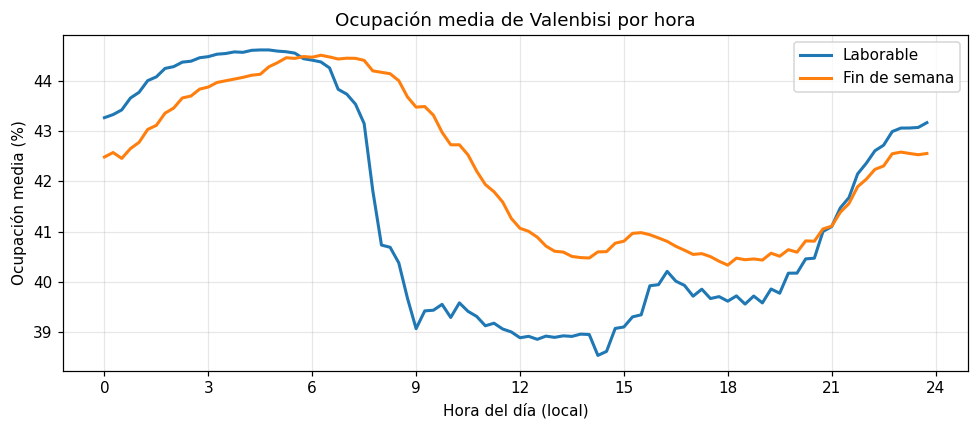

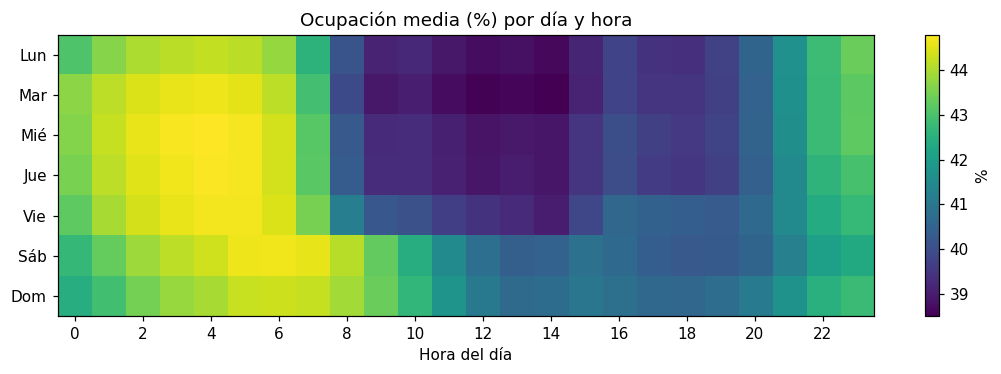

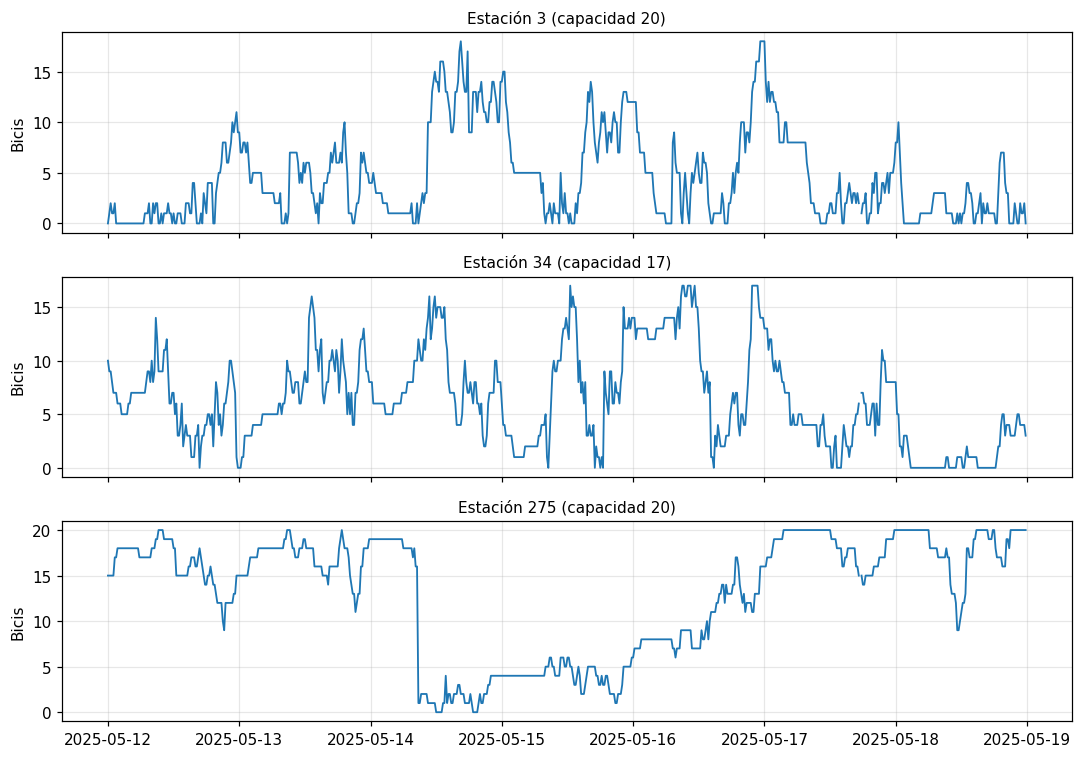

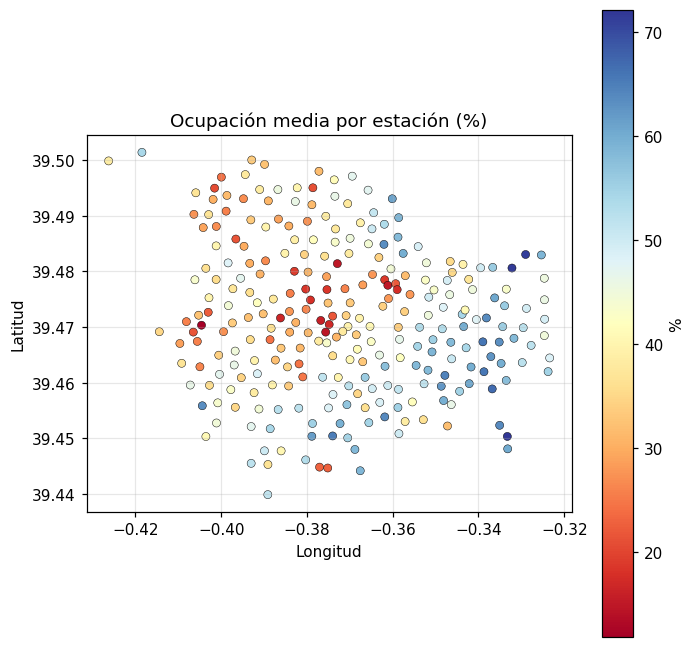

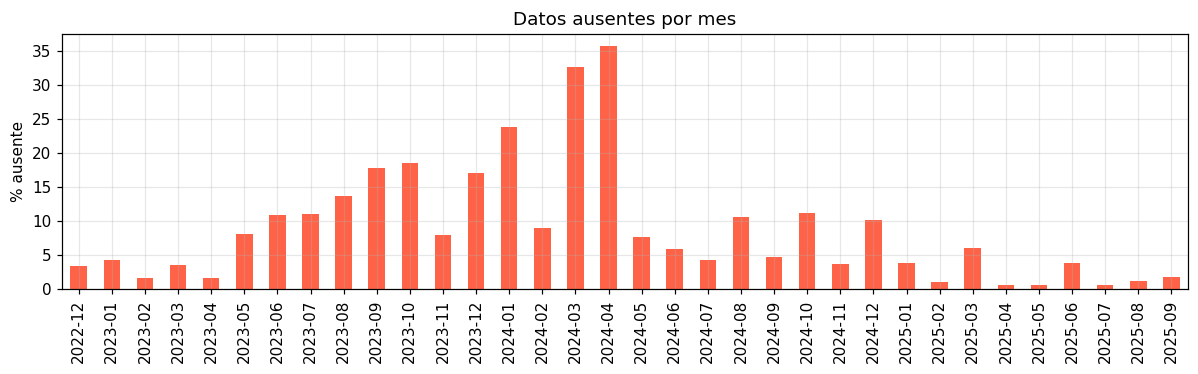

Estaciones mostradas en el gráfico 3: ['3', '34', '275']


In [6]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

bikes = pd.read_parquet("/content/drive/MyDrive/valenbisi_matriz.parquet")
info = pd.read_parquet("/content/drive/MyDrive/valenbisi_estaciones.parquet")

occ = (bikes / info.capacidad.reindex(bikes.columns)).clip(0, 1)   # 0 = vacía, 1 = llena
ciudad = occ.mean(axis=1)                                          # ocupación media de la ciudad

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

# 1) Perfil por hora: laborable vs fin de semana
f = ciudad.to_frame("occ")
f["hora"] = f.index.hour + f.index.minute / 60
f["finde"] = f.index.dayofweek >= 5
fig, ax = plt.subplots(figsize=(9, 4))
for finde, nombre in [(False, "Laborable"), (True, "Fin de semana")]:
    p = f[f.finde == finde].groupby("hora").occ.mean()
    ax.plot(p.index, p.values * 100, label=nombre, lw=2)
ax.set(xlabel="Hora del día (local)", ylabel="Ocupación media (%)",
       title="Ocupación media de Valenbisi por hora", xticks=range(0, 25, 3))
ax.legend(); plt.tight_layout(); plt.savefig("/content/drive/MyDrive/eda_1_perfil_hora.png", dpi=150); plt.show()

# 2) Mapa de calor día de la semana x hora
h = ciudad.groupby([ciudad.index.dayofweek, ciudad.index.hour]).mean().unstack() * 100
fig, ax = plt.subplots(figsize=(10, 3.5))
im = ax.imshow(h.values, aspect="auto", cmap="viridis")
ax.set(yticks=range(7), yticklabels=dias, xticks=range(0, 24, 2),
       xlabel="Hora del día", title="Ocupación media (%) por día y hora")
ax.grid(False); plt.colorbar(im, label="%"); plt.tight_layout()
plt.savefig("/content/drive/MyDrive/eda_2_heatmap.png", dpi=150); plt.show()

# 3) Tres estaciones (baja, media y alta ocupación media) durante una semana
media = occ.mean().sort_values()
elegidas = [media.index[10], media.index[len(media) // 2], media.index[-10]]
semana = slice("2025-05-12", "2025-05-18")     # lunes a domingo
fig, axs = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, s in zip(axs, elegidas):
    ax.plot(bikes.loc[semana, s], lw=1.2)
    ax.set_ylabel("Bicis"); ax.set_title(f"Estación {s} (capacidad {int(info.capacidad[s])})", fontsize=10)
plt.tight_layout(); plt.savefig("/content/drive/MyDrive/eda_3_estaciones.png", dpi=150); plt.show()

# 4) Mapa de ocupación media
fig, ax = plt.subplots(figsize=(6.5, 6))
sc = ax.scatter(info.longitude, info.latitude, c=occ.mean().reindex(info.index) * 100,
                cmap="RdYlBu", s=28, edgecolor="k", linewidth=.3)
ax.set(xlabel="Longitud", ylabel="Latitud", title="Ocupación media por estación (%)")
ax.set_aspect(1 / np.cos(np.radians(39.47)))
plt.colorbar(sc, label="%"); plt.tight_layout()
plt.savefig("/content/drive/MyDrive/eda_4_mapa.png", dpi=150); plt.show()

# 5) Datos ausentes por mes
na_mes = bikes.isna().mean(axis=1).groupby(bikes.index.to_period("M")).mean() * 100
fig, ax = plt.subplots(figsize=(11, 3.5))
na_mes.plot.bar(ax=ax, color="tomato")
ax.set(ylabel="% ausente", xlabel="", title="Datos ausentes por mes")
plt.tight_layout(); plt.savefig("/content/drive/MyDrive/eda_5_ausentes.png", dpi=150); plt.show()

print("Estaciones mostradas en el gráfico 3:", elegidas)

## 6. Partición temporal y baselines

**Partición (por fecha del objetivo, nunca aleatoria):**
- Entrenamiento: 01-12-2022 → 30-09-2024
- Validación: 01-10-2024 → 28-02-2025
- Test: 01-03-2025 → 24-09-2025 (incluye Fallas 2025)

**Horizonte:** 1 hora = 4 pasos de 15 minutos.

**Baselines:**
1. Persistencia: dentro de 1 h habrá lo mismo que ahora.
2. Misma hora de la semana anterior.
3. Perfil medio por (día de la semana, franja de 15 min, estación), calculado solo con entrenamiento.
4. Persistencia + cambio típico: valor actual más lo que suele cambiar en la siguiente hora según el perfil.

**Métricas:** MAE y RMSE en bicis, y MAE como % de la capacidad. Se evalúan sobre los mismos puntos para todos los baselines.

In [7]:
import numpy as np, pandas as pd, warnings
from google.colab import drive
drive.mount('/content/drive')
warnings.filterwarnings("ignore", category=RuntimeWarning)

bikes = pd.read_parquet("/content/drive/MyDrive/valenbisi_matriz.parquet")
info  = pd.read_parquet("/content/drive/MyDrive/valenbisi_estaciones.parquet")
Y   = bikes.to_numpy(dtype="float32")            # (tiempo, estaciones)
idx = bikes.index
T, S = Y.shape
cap = info.capacidad.reindex(bikes.columns).to_numpy(dtype="float32")

H, SEM = 4, 96 * 7        # horizonte: 4 pasos (1 h); semana: 672 pasos

splits = {
    "train": np.asarray(idx <= "2024-09-30 23:45"),
    "val":   np.asarray((idx >= "2024-10-01") & (idx <= "2025-02-28 23:45")),
    "test":  np.asarray(idx >= "2025-03-01"),
}
for k, m in splits.items():
    print(k, idx[m].min().date(), "→", idx[m].max().date(), f"({m.sum():,} pasos)")

# Perfil medio por (día de semana, franja de 15 min, estación), SOLO con train
key = (idx.dayofweek * 96 + idx.hour * 4 + idx.minute // 15).to_numpy()
prof = np.full((672, S), np.nan, dtype="float32")
for k in range(672):
    prof[k] = np.nanmean(Y[splits["train"] & (key == k)], axis=0)

# Predicciones indexadas por la hora del OBJETIVO
def vacia():
    return np.full((T, S), np.nan, dtype="float32")

P = {}
p = vacia(); p[H:] = Y[:-H]
P["1. Persistencia"] = p
p = vacia(); p[SEM:] = Y[:-SEM]
P["2. Misma hora, semana anterior"] = p
P["3. Perfil medio (día x hora)"] = prof[key]
p = vacia(); p[H:] = Y[:-H] + prof[key[H:]] - prof[key[:-H]]
P["4. Persistencia + cambio típico"] = np.clip(p, 0, cap)

# Evaluar todos sobre los MISMOS puntos
valid = ~np.isnan(Y)
for q in P.values():
    valid &= ~np.isnan(q)
capM = np.broadcast_to(cap, Y.shape)

filas = []
for nombre, q in P.items():
    for split in ["val", "test"]:
        m = valid & splits[split][:, None]
        err = (q - Y)[m]
        filas.append({"baseline": nombre, "split": split,
                      "MAE (bicis)": np.abs(err).mean(),
                      "RMSE (bicis)": np.sqrt((err ** 2).mean()),
                      "MAE (% capacidad)": 100 * (np.abs(err) / capM[m]).mean()})
res = pd.DataFrame(filas)
tabla = res.pivot_table(index="baseline", columns="split").round(2)
print("Puntos evaluados (test):", int((valid & splits["test"][:, None]).sum()))
tabla.to_csv("/content/drive/MyDrive/baselines_resultados.csv")
tabla

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
train 2022-12-01 → 2024-09-30 (64,312 pasos)
val 2024-10-01 → 2025-02-28 (14,496 pasos)
test 2025-03-01 → 2025-09-24 (19,873 pasos)
Puntos evaluados (test): 5221187


MAE (% capacidad)            MAE (bicis)  \
split                                        test        val        test   
baseline                                                                   
1. Persistencia                              7.97   7.320000        1.55   
2. Misma hora, semana anterior              24.84  24.360001        4.77   
3. Perfil medio (día x hora)                22.52  21.850000        4.38   
4. Persistencia + cambio típico              7.76   7.130000        1.50   

                                      RMSE (bicis)        
split                             val         test   val  
baseline                                                  
1. Persistencia                  1.43         2.64  2.49  
2. Misma hora, semana anterior   4.69         6.43  6.38  
3. Perfil medio (día x hora)     4.24         5.40  5.22  
4. Persistencia + cambio típico  1.38         2.43  2.26

## 7. LightGBM global (referencia no neuronal)

Un único modelo para las 273 estaciones que predice el **cambio de bicis en la próxima hora** (`bicis(t+1h) − bicis(t)`), con pérdida L1 (MAE).

**Entradas (todas conocidas en el instante t):** bicis ahora, variaciones a 15 min / 30 min / 1 h / 2 h / 4 h, valor de ayer y de la semana pasada a la hora del objetivo, perfil típico (día × hora), hora y día del objetivo, ocupación media de la ciudad, capacidad y coordenadas.

Se entrena con orígenes cada 6 pasos (uno cada 90 min) para que quepa en la memoria de Colab. **Papel en el proyecto:** si la GRU no mejora a este modelo, se documenta como resultado honesto.

In [8]:
import numpy as np, pandas as pd, lightgbm as lgb

lat = info.latitude.reindex(bikes.columns).to_numpy("float32")
lon = info.longitude.reindex(bikes.columns).to_numpy("float32")
occ_est = np.nanmean(Y[splits["train"]] / cap, axis=0).astype("float32")   # solo train
ciudad = np.nanmean(Y / cap, axis=1).astype("float32")                     # ocupación media por instante

def construir(o):
    """o = índices de instante 'ahora'. Devuelve X, y (cambio) y datos auxiliares."""
    n = len(o)
    Yo = Y[o]
    tobj = o + H
    bc = lambda v: np.broadcast_to(v, (n, S)).ravel()
    f = {
        "bicis_ahora": Yo,
        "d_15m": Yo - Y[o - 1], "d_30m": Yo - Y[o - 2], "d_1h": Yo - Y[o - 4],
        "d_2h": Yo - Y[o - 8], "d_4h": Yo - Y[o - 16],
        "ayer_objetivo": Y[tobj - 96], "semana_objetivo": Y[tobj - SEM],
        "perfil_objetivo": prof[key[tobj]],
        "perfil_cambio": prof[key[tobj]] - prof[key[o]],
    }
    X = {k: v.ravel() for k, v in f.items()}
    X["franja_objetivo"] = bc((key[tobj] % 96)[:, None])
    X["dia_objetivo"] = bc((key[tobj] // 96)[:, None])
    X["ciudad_ahora"] = bc(ciudad[o][:, None])
    X["ciudad_d_1h"] = bc((ciudad[o] - ciudad[o - 4])[:, None])
    X["capacidad"] = bc(cap[None, :]); X["lat"] = bc(lat[None, :]); X["lon"] = bc(lon[None, :])
    X["ocup_media_est"] = bc(occ_est[None, :])
    X = pd.DataFrame(X).astype("float32")
    y = Y[tobj].ravel()
    ahora = Yo.ravel()
    capf = bc(cap[None, :])
    ok = ~np.isnan(y) & ~np.isnan(ahora) & ~np.isnan(X["perfil_cambio"].to_numpy())
    return X[ok].reset_index(drop=True), (y - ahora)[ok], ahora[ok], capf[ok], y[ok]

# Orígenes: el instante objetivo (o+H) debe caer en cada partición
todos = np.arange(SEM, T - H)
def origenes(split, paso):
    return todos[splits[split][todos + H]][::paso]

Xtr, ytr, *_ = construir(origenes("train", 6))
Xva, yva, *_ = construir(origenes("val", 8))
print("Filas train:", len(Xtr), "| val:", len(Xva))

params = dict(objective="l1", learning_rate=0.1, num_leaves=127, min_data_in_leaf=200,
              feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, verbose=-1)
model = lgb.train(params, lgb.Dataset(Xtr, ytr), num_boost_round=600,
                  valid_sets=[lgb.Dataset(Xva, yva)],
                  callbacks=[lgb.early_stopping(30), lgb.log_evaluation(50)])
model.save_model("/content/drive/MyDrive/lgbm_valenbisi.txt")

# Test: mismos puntos para todos los métodos
Xte, yte, ahora_te, cap_te, y_te = construir(origenes("test", 2))
pred = np.clip(ahora_te + model.predict(Xte, num_iteration=model.best_iteration), 0, cap_te)
pers = ahora_te
base4 = np.clip(ahora_te + Xte["perfil_cambio"].to_numpy(), 0, cap_te)

def met(p):
    e = p - y_te
    return dict(MAE=np.abs(e).mean(), RMSE=np.sqrt((e ** 2).mean()),
                MAE_pct_cap=100 * (np.abs(e) / cap_te).mean())
res = pd.DataFrame({"Persistencia": met(pers), "Baseline 4": met(base4),
                    "LightGBM": met(pred)}).T.round(3)
print("Puntos de test:", len(y_te))
print(res)
mejora = 100 * (1 - res.loc["LightGBM", "MAE"] / res.loc["Baseline 4", "MAE"])
print(f"\nMejora del MAE de LightGBM frente al baseline 4: {mejora:.1f} %")

imp = pd.Series(model.feature_importance("gain"), index=Xtr.columns).sort_values(ascending=False)
print("\nVariables más útiles (ganancia):")
print((100 * imp / imp.sum()).round(1).head(10))

Filas train: 2513779 | val: 460795
Training until validation scores don't improve for 30 rounds
[50]	valid_0's l1: 1.31617
[100]	valid_0's l1: 1.31131
[150]	valid_0's l1: 1.30967
[200]	valid_0's l1: 1.30877
[250]	valid_0's l1: 1.30825
[300]	valid_0's l1: 1.30785
[350]	valid_0's l1: 1.30737
[400]	valid_0's l1: 1.30705
[450]	valid_0's l1: 1.30683
[500]	valid_0's l1: 1.30667
[550]	valid_0's l1: 1.30659
[600]	valid_0's l1: 1.30653
Did not meet early stopping. Best iteration is:
[599]	valid_0's l1: 1.30653
Puntos de test: 2644599
                MAE   RMSE  MAE_pct_cap
Persistencia  1.548  2.632        7.966
Baseline 4    1.499  2.432        7.765
LightGBM      1.430  2.331        7.417

Mejora del MAE de LightGBM frente al baseline 4: 4.6 %

Variables más útiles (ganancia):
perfil_cambio      21.6
bicis_ahora        10.6
perfil_objetivo     7.5
ciudad_d_1h         7.4
ayer_objetivo       6.4
ciudad_ahora        6.4
franja_objetivo     6.2
lon                 5.6
lat                 5.1
sem

## 8. Análisis de errores

LightGBM mejora un 4,6 % al mejor baseline, lejos del 15 % planteado. Antes de entrenar más modelos se mira **dónde acierta y dónde falla**: error por hora del día, laborable frente a fin de semana, y comportamiento cuando la estación se queda vacía.

       pers  base4   lgbm  mejora_vs_base4_%
hora                                        
0     1.503  1.465  1.391              5.066
1     1.325  1.304  1.242              4.750
2     0.897  0.905  0.856              5.469
3     0.633  0.657  0.610              7.157
4     0.504  0.538  0.491              8.733
5     0.460  0.508  0.461              9.305
6     0.520  0.567  0.521              8.214
7     0.902  0.914  0.863              5.621
8     1.916  1.546  1.496              3.277
9     2.267  1.853  1.665             10.167
10    1.912  1.761  1.669              5.235
11    1.756  1.711  1.641              4.099
12    1.797  1.782  1.703              4.424
13    1.781  1.785  1.715              3.944
14    1.896  1.852  1.779              3.937
15    2.096  1.975  1.899              3.882
16    1.870  1.845  1.782              3.393
17    1.761  1.783  1.733              2.818
18    1.901  1.908  1.846              3.268
19    2.031  2.019  1.946              3.625
20    2.07

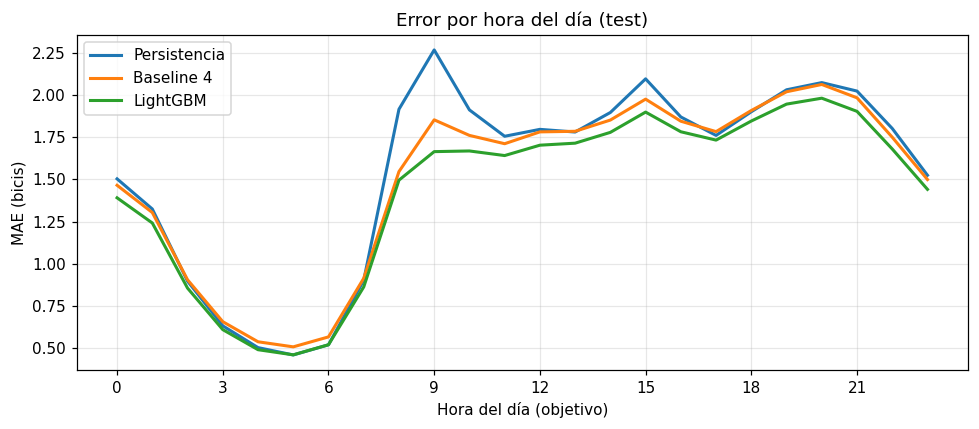


MAE por tipo de día:
        pers  base4   lgbm
finde                     
False  1.606  1.545  1.469
True   1.400  1.384  1.331

Frecuencia real de 'sin bicis': 10.2%
Persistencia  precisión 57.9% | recall 57.9% | avisos: 269,450
LightGBM      precisión 68.7% | recall 49.2% | avisos: 192,954

MAE cuando hay 0 bicis real: 1.097 | MAE en el resto: 1.468


In [9]:
import matplotlib.pyplot as plt

e = pd.DataFrame({
    "hora":  (Xte["franja_objetivo"].to_numpy() // 4).astype(int),
    "finde": Xte["dia_objetivo"].to_numpy() >= 5,
    "pers":  np.abs(pers - y_te),
    "base4": np.abs(base4 - y_te),
    "lgbm":  np.abs(pred - y_te),
})

# 1) Error por hora del día
ph = e.groupby("hora")[["pers", "base4", "lgbm"]].mean()
ph["mejora_vs_base4_%"] = 100 * (1 - ph.lgbm / ph.base4)
print(ph.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
for c, n in [("pers", "Persistencia"), ("base4", "Baseline 4"), ("lgbm", "LightGBM")]:
    ax.plot(ph.index, ph[c], label=n, lw=2)
ax.set(xlabel="Hora del día (objetivo)", ylabel="MAE (bicis)",
       title="Error por hora del día (test)", xticks=range(0, 24, 3))
ax.legend(); ax.grid(alpha=.3); plt.tight_layout()
plt.savefig("/content/drive/MyDrive/err_1_por_hora.png", dpi=150); plt.show()

# 2) Laborable vs fin de semana
print("\nMAE por tipo de día:")
print(e.groupby("finde")[["pers", "base4", "lgbm"]].mean().round(3))

# 3) ¿Se quedará la estación sin bicis dentro de 1 hora?
real0 = (y_te == 0)
print(f"\nFrecuencia real de 'sin bicis': {real0.mean():.1%}")
for nombre, p in [("Persistencia", pers), ("LightGBM", pred)]:
    a0 = p < 0.5
    tp = (a0 & real0).sum()
    prec = tp / max(a0.sum(), 1)
    rec = tp / max(real0.sum(), 1)
    print(f"{nombre:13s} precisión {prec:.1%} | recall {rec:.1%} | avisos: {a0.sum():,}")

print("\nMAE cuando hay 0 bicis real:", np.abs(pred - y_te)[real0].mean().round(3),
      "| MAE en el resto:", np.abs(pred - y_te)[~real0].mean().round(3))

## 9. ¿Sabe el modelo avisar de estaciones que se van a vaciar?

Con un umbral arbitrario (< 0,5 bicis), el regresor no es comparable a la persistencia. Se hacen dos comprobaciones:

1. **Barrido del umbral** para ver el equilibrio precisión/recall.
2. Evaluación solo sobre las **estaciones que hoy tienen bicis y en 1 h ya no**, el único caso donde un modelo puede aportar algo que la persistencia no (su recall ahí es 0 por construcción).

**Nota de procedimiento:** estos umbrales se miraron sobre test, así que las cifras absolutas son algo optimistas.

In [10]:
real0 = (y_te == 0)

# 1) Barrido de umbrales (todos los casos)
print("Todos los casos (referencia: persistencia = precisión 57.9 %, recall 57.9 %, F1 0.579)")
print("umbral | precisión | recall |   F1  |  avisos")
for u in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5]:
    a = pred < u
    tp = (a & real0).sum()
    p = tp / max(a.sum(), 1); r = tp / real0.sum()
    print(f"<{u:<5}| {p:8.1%}  | {r:6.1%} | {2*p*r/(p+r):.3f} | {a.sum():,}")

# 2) Solo estaciones que HOY tienen bicis y en 1 h se quedan vacías
hay_ahora = ahora_te > 0
nuevas = real0 & hay_ahora
print(f"\nHoy hay bicis y en 1 h no: {nuevas.sum():,} casos "
      f"({nuevas.sum() / hay_ahora.sum():.1%} de los casos que hoy tienen bicis)")
print("Persistencia: recall 0 % en este grupo (por construcción)")
print("umbral | precisión | recall | avisos")
for u in [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]:
    a = hay_ahora & (pred < u)
    tp = (a & real0).sum()
    p = tp / max(a.sum(), 1); r = tp / nuevas.sum()
    print(f"<{u:<5}| {p:8.1%}  | {r:6.1%} | {a.sum():,}")

Todos los casos (referencia: persistencia = precisión 57.9 %, recall 57.9 %, F1 0.579)
umbral | precisión | recall |   F1  |  avisos
<0.5  |    68.7%  |  49.2% | 0.574 | 192,954
<0.75 |    65.0%  |  54.8% | 0.595 | 226,959
<1.0  |    55.1%  |  64.0% | 0.592 | 313,276
<1.25 |    47.1%  |  73.2% | 0.573 | 419,365
<1.5  |    45.2%  |  76.7% | 0.569 | 457,527
<2.0  |    39.8%  |  83.1% | 0.538 | 563,433
<2.5  |    35.4%  |  87.7% | 0.504 | 667,965

Hoy hay bicis y en 1 h no: 113,464 casos (4.8% de los casos que hoy tienen bicis)
Persistencia: recall 0 % en este grupo (por construcción)
umbral | precisión | recall | avisos
<0.5  |    51.7%  |   3.7% | 8,171
<1.0  |    31.6%  |  25.1% | 90,060
<1.5  |    26.2%  |  49.3% | 213,265
<2.0  |    22.8%  |  61.9% | 307,858
<2.5  |    20.0%  |  71.7% | 405,999
<3.0  |    17.9%  |  78.6% | 497,371


## 10. Clasificador de "estación vacía en 1 hora" y comparación justa

Se entrena un **clasificador LightGBM** (objetivo: bicis dentro de 1 h = 0) y se compara, sin depender de un umbral, con una regla simple ("cuantas menos bicis hay ahora, más riesgo"), el baseline 4 y el regresor.

**Métricas:** precisión media (AP), precisión al detectar el 50 % de los vaciados y recall con una precisión mínima del 30 %. Se evalúa en todos los casos y en el subgrupo "hoy hay bicis" (tasa base 4,8 %).

In [11]:
import lightgbm as lgb, numpy as np, pandas as pd
from sklearn.metrics import average_precision_score, precision_recall_curve

# Etiqueta: ¿0 bicis dentro de 1 h?  (bicis_ahora + cambio = valor futuro)
ctr = ((Xtr["bicis_ahora"].to_numpy() + ytr) == 0).astype(int)
cva = ((Xva["bicis_ahora"].to_numpy() + yva) == 0).astype(int)
cte = (y_te == 0).astype(int)
print(f"Tasa de vacías: train {ctr.mean():.1%} | val {cva.mean():.1%} | test {cte.mean():.1%}")

params = dict(objective="binary", metric="average_precision", learning_rate=0.1,
              num_leaves=63, min_data_in_leaf=200, feature_fraction=0.8,
              bagging_fraction=0.8, bagging_freq=1, verbose=-1)
clf = lgb.train(params, lgb.Dataset(Xtr, ctr), num_boost_round=400,
                valid_sets=[lgb.Dataset(Xva, cva)],
                callbacks=[lgb.early_stopping(30), lgb.log_evaluation(50)])
clf.save_model("/content/drive/MyDrive/lgbm_clasificador_vacia.txt")
prob = clf.predict(Xte, num_iteration=clf.best_iteration)

# Todos los scores: mayor valor = más riesgo de estar vacía
scores = {
    "Regla: pocas bicis ahora": -ahora_te,
    "Baseline 4 (bicis previstas)": -base4,
    "LightGBM regresor": -pred,
    "LightGBM clasificador": prob,
}

def resumen(y, s):
    ap = average_precision_score(y, s)
    p, r, _ = precision_recall_curve(y, s)
    return dict(AP=ap,
                precision_con_recall50=p[r >= 0.5].max(),
                recall_con_precision30=r[p >= 0.3].max())

for nombre, mask in [("TODOS LOS CASOS", np.ones(len(y_te), bool)),
                     ("SOLO DONDE HOY HAY BICIS", ahora_te > 0)]:
    y = cte[mask]
    print(f"\n{nombre}  (tasa base {y.mean():.1%}, {mask.sum():,} casos)")
    tabla = pd.DataFrame({k: resumen(y, v[mask]) for k, v in scores.items()}).T
    print((tabla * 100).round(1).rename(columns={
        "AP": "AP %", "precision_con_recall50": "Precisión al 50% recall %",
        "recall_con_precision30": "Recall con 30% precisión %"}))

Tasa de vacías: train 9.2% | val 10.6% | test 10.2%
Training until validation scores don't improve for 30 rounds
[50]	valid_0's average_precision: 0.685494
[100]	valid_0's average_precision: 0.690742
[150]	valid_0's average_precision: 0.692221
[200]	valid_0's average_precision: 0.692765
[250]	valid_0's average_precision: 0.692909
Early stopping, best iteration is:
[246]	valid_0's average_precision: 0.692977

TODOS LOS CASOS  (tasa base 10.2%, 2,644,599 casos)
                              AP %  Precisión al 50% recall %  \
Regla: pocas bicis ahora      48.0                       57.9   
Baseline 4 (bicis previstas)  53.5                       62.7   
LightGBM regresor             62.1                       68.2   
LightGBM clasificador         66.5                       69.2   

                              Recall con 30% precisión %  
Regla: pocas bicis ahora                            86.0  
Baseline 4 (bicis previstas)                        91.4  
LightGBM regresor                

## 11. Red neuronal: GRU con dos salidas

> **Requiere GPU** (*Entorno de ejecución → Cambiar tipo de entorno → T4 GPU*). Esta celda es autónoma: recarga los datos desde Drive y reconstruye la partición. Cambiar de entorno reinicia la sesión, y no importa.

Una GRU global (un único modelo para las 273 estaciones) que lee las últimas 4 h (16 pasos) de cada estación y predice, para dentro de 1 h:
1. El **cambio de bicis** (pérdida L1).
2. La **probabilidad de que la estación esté vacía** (entropía cruzada).

**Entradas por paso:** ocupación, marca de dato ausente, ocupación media de la ciudad y perfil típico (día × hora).
**Entradas estáticas:** capacidad, coordenadas, ocupación media, hora y día del objetivo, perfil del objetivo, valor de ayer y de la semana anterior.

**Protocolo:** hiperparámetros fijados de antemano, mejor época elegida con **validación**, y el test se usa **una sola vez** al final. Se compara con LightGBM (MAE 1,430; AP del subgrupo 31,3).

In [12]:
import time, warnings, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import average_precision_score, precision_recall_curve
from google.colab import drive
warnings.filterwarnings("ignore")
drive.mount('/content/drive')
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", dev)
torch.manual_seed(0); np.random.seed(0)

# ---------- 1) Datos y partición (igual que antes) ----------
bikes = pd.read_parquet("/content/drive/MyDrive/valenbisi_matriz.parquet")
info  = pd.read_parquet("/content/drive/MyDrive/valenbisi_estaciones.parquet")
Y = bikes.to_numpy("float32"); idx = bikes.index; T, S = Y.shape
cap = info.capacidad.reindex(bikes.columns).to_numpy("float32")
lat = info.latitude.reindex(bikes.columns).to_numpy("float32")
lon = info.longitude.reindex(bikes.columns).to_numpy("float32")
H, SEM, L = 4, 672, 16

splits = {
    "train": np.asarray(idx <= "2024-09-30 23:45"),
    "val":   np.asarray((idx >= "2024-10-01") & (idx <= "2025-02-28 23:45")),
    "test":  np.asarray(idx >= "2025-03-01"),
}
key = (idx.dayofweek * 96 + idx.hour * 4 + idx.minute // 15).to_numpy()
tr = splits["train"]
prof = pd.DataFrame(Y[tr]).groupby(key[tr]).mean().reindex(range(672)).to_numpy("float32")
occ_est = np.nanmean(Y[tr] / cap, axis=0).astype("float32")
ciudad  = np.nanmean(Y / cap, axis=1).astype("float32")

todos = np.arange(SEM, T - H)
def pares(split, paso, exigir_perfil=False):
    O = todos[splits[split][todos + H]][::paso]
    o = np.repeat(O, S); s = np.tile(np.arange(S), len(O))
    ok = ~np.isnan(Y[o, s]) & ~np.isnan(Y[o + H, s])
    if exigir_perfil:      # mismo filtro que con LightGBM
        ok &= ~np.isnan(prof[key[o + H], s]) & ~np.isnan(prof[key[o], s])
    return o[ok], s[ok]

# ---------- 2) Tensores en el dispositivo ----------
tt_ = lambda a, dt=torch.float32: torch.tensor(a, dtype=dt, device=dev)
Yocc = np.clip(Y / cap, 0, 1)
Yocc_t = tt_(np.nan_to_num(Yocc, nan=0.0)); Mask_t = tt_(np.isnan(Yocc))
Yb_t = tt_(np.nan_to_num(Y, nan=0.0))
prof_occ = prof / cap
prof_occ = np.where(np.isnan(prof_occ), occ_est[None, :], prof_occ).astype("float32")
prof_t = tt_(prof_occ); key_t = tt_(key, torch.long)
ciu_t = tt_(np.nan_to_num(ciudad, nan=0.4)); capT = tt_(cap)
st_t = tt_(np.stack([cap / 40, (lat - lat.mean()) / lat.std(),
                     (lon - lon.mean()) / lon.std(), occ_est], 1))
offs = torch.arange(-(L - 1), 1, device=dev)

def batch(o, s):
    tt = o[:, None] + offs[None, :]; ss = s[:, None].expand_as(tt)
    seq = torch.stack([Yocc_t[tt, ss], Mask_t[tt, ss], ciu_t[tt],
                       prof_t[key_t[tt], ss]], dim=-1)                 # (B, L, 4)
    tobj = o + H; k = key_t[tobj]; fr = (k % 96).float()
    stat = torch.cat([st_t[s],
        torch.sin(2 * np.pi * fr / 96)[:, None], torch.cos(2 * np.pi * fr / 96)[:, None],
        F.one_hot(k // 96, 7).float(),
        prof_t[k, s][:, None], (prof_t[k, s] - prof_t[key_t[o], s])[:, None],
        Yocc_t[tobj - 96, s][:, None], Yocc_t[tobj - SEM, s][:, None],
        Mask_t[tobj - 96, s][:, None], Mask_t[tobj - SEM, s][:, None]], dim=1)
    return seq, stat

# ---------- 3) Modelo ----------
class Red(nn.Module):
    def __init__(self, n_seq, n_stat, h=64):
        super().__init__()
        self.gru = nn.GRU(n_seq, h, batch_first=True)
        self.mlp = nn.Sequential(nn.Linear(h + n_stat, 128), nn.ReLU(),
                                 nn.Linear(128, 64), nn.ReLU())
        self.reg = nn.Linear(64, 1); self.cls = nn.Linear(64, 1)
    def forward(self, seq, stat):
        _, hN = self.gru(seq)
        z = self.mlp(torch.cat([hN[-1], stat], 1))
        return self.reg(z).squeeze(1), self.cls(z).squeeze(1)

def perdida(a, b, o, s):
    ahora, y = Yb_t[o, s], Yb_t[o + H, s]
    l1 = (a * 5 - (y - ahora)).abs().mean()            # la salida a va en unidades de 5 bicis
    bce = F.binary_cross_entropy_with_logits(b, (y == 0).float())
    return l1, bce

def salida(o, s, bs=16384):
    red.eval(); A, B = [], []
    with torch.no_grad():
        for i in range(0, len(o), bs):
            a, b = red(*batch(o[i:i + bs], s[i:i + bs])); A.append(a); B.append(b)
    return torch.cat(A), torch.cat(B)

# ---------- 4) Entrenamiento (la época se elige con VALIDACIÓN) ----------
o_tr, s_tr = [tt_(a, torch.long) for a in pares("train", 4)]
o_va, s_va = [tt_(a, torch.long) for a in pares("val", 8)]
print(f"Pares: train {len(o_tr):,} | val {len(o_va):,}")
seq0, stat0 = batch(o_va[:2], s_va[:2])
red = Red(seq0.shape[2], stat0.shape[1]).to(dev)
EPOCHS, BS = 8, 4096
opt = torch.optim.Adam(red.parameters(), lr=2e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

mejor, estado = 1e9, None
for ep in range(EPOCHS):
    t0 = time.time(); red.train()
    perm = torch.randperm(len(o_tr), device=dev)
    for i in range(0, len(perm), BS):
        j = perm[i:i + BS]; o, s = o_tr[j], s_tr[j]
        a, b = red(*batch(o, s)); l1, bce = perdida(a, b, o, s)
        opt.zero_grad(); (l1 + bce).backward(); opt.step()
    sched.step()
    a, b = salida(o_va, s_va); l1v, bcev = perdida(a, b, o_va, s_va)
    print(f"Época {ep+1}/{EPOCHS} | val L1 {l1v.item():.4f} | val BCE {bcev.item():.4f} | {time.time()-t0:.0f}s")
    if (l1v + bcev).item() < mejor:
        mejor = (l1v + bcev).item(); estado = {k: v.clone() for k, v in red.state_dict().items()}
red.load_state_dict(estado)
torch.save(estado, "/content/drive/MyDrive/gru_valenbisi.pt")

# ---------- 5) TEST (una sola vez) ----------
o_np, s_np = pares("test", 2, exigir_perfil=True)
print(f"\nPuntos de test: {len(o_np):,}  (con LightGBM fueron 2,644,599)")
a, b = salida(tt_(o_np, torch.long), tt_(s_np, torch.long))
ahora, y, c = Y[o_np, s_np], Y[o_np + H, s_np], cap[s_np]
pred = np.clip(ahora + 5 * a.cpu().numpy(), 0, c)
prob = torch.sigmoid(b).cpu().numpy()
base4 = np.clip(ahora + prof[key[o_np + H], s_np] - prof[key[o_np], s_np], 0, c)

def mae(p):
    e = p - y
    return np.abs(e).mean(), np.sqrt((e ** 2).mean()), 100 * (np.abs(e) / c).mean()
res = pd.DataFrame({"Persistencia": mae(ahora), "Baseline 4": mae(base4), "GRU": mae(pred)},
                   index=["MAE", "RMSE", "MAE % cap"]).T.round(3)
res.loc["LightGBM (ref.)"] = [1.430, 2.331, 7.417]
print(res)
print(f"Mejora MAE de la GRU: {100*(1-res.loc['GRU','MAE']/res.loc['Baseline 4','MAE']):.1f} % vs baseline 4 | "
      f"{100*(1-res.loc['GRU','MAE']/res.loc['LightGBM (ref.)','MAE']):.1f} % vs LightGBM")

def resumen(yv, sc):
    p, r, _ = precision_recall_curve(yv, sc)
    return dict(AP=average_precision_score(yv, sc), prec_r50=p[r >= .5].max(), rec_p30=r[p >= .3].max())
vac = (y == 0).astype(int)
scores = {"Regla: pocas bicis": -ahora, "Baseline 4": -base4,
          "GRU regresor": -pred, "GRU clasificador": prob}
for nombre, m in [("TODOS LOS CASOS", np.ones(len(y), bool)), ("SOLO DONDE HOY HAY BICIS", ahora > 0)]:
    print(f"\n{nombre} (tasa base {vac[m].mean():.1%})")
    print((pd.DataFrame({k: resumen(vac[m], v[m]) for k, v in scores.items()}).T * 100).round(1))
print("\nReferencia LightGBM clasificador -> TODOS: AP 66.5 | SUBGRUPO: AP 31.3, prec@r50 29.7, rec@p30 48.7")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dispositivo: cuda
Pares: train 3,750,041 | val 460,795
Época 1/8 | val L1 1.3367 | val BCE 0.1895 | 8s
Época 2/8 | val L1 1.3346 | val BCE 0.1910 | 7s
Época 3/8 | val L1 1.3158 | val BCE 0.1813 | 7s
Época 4/8 | val L1 1.3037 | val BCE 0.1790 | 7s
Época 5/8 | val L1 1.3039 | val BCE 0.1788 | 7s
Época 6/8 | val L1 1.3013 | val BCE 0.1791 | 7s
Época 7/8 | val L1 1.2976 | val BCE 0.1780 | 7s
Época 8/8 | val L1 1.2961 | val BCE 0.1768 | 7s

Puntos de test: 2,644,599  (con LightGBM fueron 2,644,599)
                   MAE   RMSE  MAE % cap
Persistencia     1.548  2.632      7.966
Baseline 4       1.499  2.432      7.765
GRU              1.415  2.311      7.348
LightGBM (ref.)  1.430  2.331      7.417
Mejora MAE de la GRU: 5.6 % vs baseline 4 | 1.0 % vs LightGBM

TODOS LOS CASOS (tasa base 10.2%)
                      AP  prec_r50  rec_p30
Regla: pocas bicis  48.0  

## 12. Estabilidad de la GRU: 5 semillas y conjunto

Se entrenan 5 GRU con semillas distintas (misma configuración, época elegida con validación) para medir la media y la desviación del MAE y del AP en test, y el resultado del **conjunto** (promedio de las 5).

> Ejecutar **justo después de la sección anterior**, en la misma sesión: reutiliza sus variables.

Las decisiones (épocas, tamaño) se toman solo con validación. El test solo se informa, no se usa para elegir nada.

In [13]:
def entrenar(seed, epochs=8, h=64):
    global red
    torch.manual_seed(seed); np.random.seed(seed)
    red = Red(seq0.shape[2], stat0.shape[1], h=h).to(dev)
    opt = torch.optim.Adam(red.parameters(), lr=2e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    mejor, estado, l1_mejor = 1e9, None, None
    for ep in range(epochs):
        red.train()
        perm = torch.randperm(len(o_tr), device=dev)
        for i in range(0, len(perm), BS):
            j = perm[i:i + BS]; o, s = o_tr[j], s_tr[j]
            a, b = red(*batch(o, s)); l1, bce = perdida(a, b, o, s)
            opt.zero_grad(); (l1 + bce).backward(); opt.step()
        sched.step()
        a, b = salida(o_va, s_va); l1v, bcev = perdida(a, b, o_va, s_va)
        if (l1v + bcev).item() < mejor:
            mejor = (l1v + bcev).item(); l1_mejor = l1v.item()
            estado = {k: v.clone() for k, v in red.state_dict().items()}
    red.load_state_dict(estado)
    return l1_mejor

o_t, s_t = tt_(o_np, torch.long), tt_(s_np, torch.long)
sub = ahora > 0
filas, A_all, P_all = [], [], []
for seed in range(5):
    t0 = time.time()
    l1_val = entrenar(seed)
    a, b = salida(o_t, s_t)
    a = a.cpu().numpy(); p = torch.sigmoid(b).cpu().numpy()
    A_all.append(a); P_all.append(p)
    pr = np.clip(ahora + 5 * a, 0, c)
    filas.append(dict(semilla=seed, val_L1=l1_val, test_MAE=np.abs(pr - y).mean(),
                      AP_todos=100 * average_precision_score(vac, p),
                      AP_subgrupo=100 * average_precision_score(vac[sub], p[sub])))
    print(f"Semilla {seed} lista ({time.time()-t0:.0f}s)")

tab = pd.DataFrame(filas).set_index("semilla").round(4)
print(tab)
print("\nMedia:", tab.mean().round(4).to_dict())
print("Desv.:", tab.std().round(4).to_dict())

# Conjunto de las 5 GRU
a_m = np.mean(A_all, axis=0); p_m = np.mean(P_all, axis=0)
pr = np.clip(ahora + 5 * a_m, 0, c)
print(f"\nCONJUNTO 5 GRU -> MAE {np.abs(pr - y).mean():.4f} | "
      f"AP todos {100*average_precision_score(vac, p_m):.1f} | "
      f"AP subgrupo {100*average_precision_score(vac[sub], p_m[sub]):.1f}")
print("Referencia LightGBM -> MAE 1.4300 | AP todos 66.5 | AP subgrupo 31.3")

Semilla 0 lista (63s)
Semilla 1 lista (64s)
Semilla 2 lista (67s)
Semilla 3 lista (64s)
Semilla 4 lista (65s)
         val_L1  test_MAE  AP_todos  AP_subgrupo
semilla                                         
0        1.2961    1.4153   65.4227      31.0886
1        1.2982    1.4175   65.4374      31.1462
2        1.2986    1.4172   65.2325      30.9660
3        1.2971    1.4157   65.4939      31.2064
4        1.2965    1.4160   65.6106      31.3232

Media: {'val_L1': 1.2973, 'test_MAE': 1.4163, 'AP_todos': 65.4394, 'AP_subgrupo': 31.1461}
Desv.: {'val_L1': 0.0011, 'test_MAE': 0.001, 'AP_todos': 0.1373, 'AP_subgrupo': 0.133}

CONJUNTO 5 GRU -> MAE 1.4136 | AP todos 65.8 | AP subgrupo 31.5
Referencia LightGBM -> MAE 1.4300 | AP todos 66.5 | AP subgrupo 31.3


## 13. Exportar predicciones para la demo

Se guardan las predicciones del conjunto de 5 GRU sobre el periodo de test (mar-sep 2025) para que la app de la demo funcione sin PyTorch: valor real, valor actual, predicción de la GRU, baseline 4, probabilidad de estación vacía y capacidad. `ts_origen + 1 h` es el instante predicho.

In [14]:
demo = pd.DataFrame({
    "ts_origen":  idx[o_np],
    "estacion":   pd.Categorical(bikes.columns[s_np]),
    "ahora":      ahora.astype("float32"),
    "real":       y.astype("float32"),
    "pred_gru":   np.clip(ahora + 5 * a_m, 0, c).astype("float32"),
    "pred_base4": base4.astype("float32"),
    "prob_vacia": p_m.astype("float32"),
    "capacidad":  c.astype("float32"),
})
demo.to_parquet("/content/drive/MyDrive/valenbisi_demo_predicciones.parquet",
                compression="zstd", index=False)
import os
print(demo.shape, round(os.path.getsize("/content/drive/MyDrive/valenbisi_demo_predicciones.parquet") / 1e6, 1), "MB")
print(demo.ts_origen.min(), "→", demo.ts_origen.max())
demo.head()

(2644599, 8) 36.0 MB
2025-02-28 23:00:00 → 2025-09-23 23:00:00


,ts_origen,estacion,ahora,real,pred_gru,pred_base4,prob_vacia,capacidad
0,2025-02-28 23:00:00,1,12.0,15.0,11.864908,12.145604,0.001114,25.0
1,2025-02-28 23:00:00,10,7.0,10.0,6.543716,6.650183,0.006974,15.0
2,2025-02-28 23:00:00,100,14.0,12.0,14.899219,14.101648,0.000458,20.0
3,2025-02-28 23:00:00,101,11.0,10.0,12.167547,11.048714,0.004809,30.0
4,2025-02-28 23:00:00,102,12.0,17.0,12.325351,12.302198,0.001220,20.0


## 14. Conclusiones

| Método | MAE test (bicis) |
|---|---|
| Persistencia | 1,548 |
| Persistencia + cambio típico (mejor baseline) | 1,499 |
| LightGBM | 1,430 |
| GRU (media de 5 semillas) | 1,416 |

- La GRU y LightGBM son **equivalentes en la práctica**: cada uno gana en una métrica, por menos de un 1 %. Ambos mejoran al mejor baseline en torno al **5,5 %** (el objetivo inicial era 15 %, no alcanzado).
- El modelo aporta más en la hora punta de la mañana (8-9 h), donde la persistencia falla más.
- Como detector de estaciones que hoy tienen bicis y se vaciarán en 1 h (4,8 % de los casos), los modelos superan con claridad a las reglas sencillas (AP ≈ 31 % frente a 19-25 %), aunque con muchas falsas alarmas.
- **Limitaciones:** el objetivo de la alerta se definió tras explorar los datos; el test se consultó varias veces; faltan ~78 días (entre ellos las Fallas de 2024); no se usan meteorología ni eventos; los saltos bruscos (reposiciones, averías) no son predecibles con estos datos.
- **Siguientes pasos posibles:** añadir meteorología, mejorar LightGBM con el mismo esfuerzo que la GRU, y una fuente de datos en directo para que la demo no dependa de histórico.